# Detecting Digital and App Fraud under Heavy Class Imbalance

**Context.** The South African Banking Risk Information Centre (SABRIC) recorded 110,074 digital banking
crime incidents in 2025, with client claims of R2.41bn, up 29.2% on 2024. Banking apps accounted for about
89% of cases. The apps were not hacked: criminals tricked customers first, then used the app to add
beneficiaries and move money. A fraud model therefore has to spot a rare, legitimate-looking payment
among millions of normal ones.

**Aim.** Compare standard ways of handling extreme class imbalance for fraud detection, and judge them with
metrics that suit rare events (**PR-AUC, precision, recall**), not accuracy.

**Datasets (loaded directly in code, nothing to download by hand):**

| Dataset | What it is | How it is loaded |
|---|---|---|
| Credit Card Fraud (ULB) | 284,807 card transactions, 492 frauds (0.17%), 28 anonymised PCA features + Time + Amount | `tf.keras.utils.get_file` from the TensorFlow-hosted copy |
| PaySim | Synthetic mobile-money transactions (about 6.3M rows) built from real African mobile-money logs | `kagglehub` |

**Method.** CRISP-DM: understand, explore, prepare, model, evaluate. Split is **chronological**
(70% train / 15% validation / 15% test) because a bank scores future transactions, not a random mix.

**Models.** Logistic Regression (class weights), Logistic Regression + SMOTE, Random Forest (balanced),
XGBoost (`scale_pos_weight`) and a Keras MLP (class weights).

## 1. Setup

Install the libraries this notebook needs that may be missing (safe to re-run; it skips what is already installed).

In [1]:
%pip install -q imbalanced-learn xgboost kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install jinja2


   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, time, warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

RUN_PAYSIM = True        # set False to run on the credit card dataset only
PAYSIM_ROWS = 500_000    # random sample of PaySim rows (full file is ~6.3M); raise if you have the RAM
print("TensorFlow", tf.__version__, "| XGBoost", xgb.__version__)

TensorFlow 2.21.0 | XGBoost 3.4.1


## 2. Load the data

The credit card data comes from the copy that TensorFlow hosts for its imbalanced-data tutorial
(same ULB dataset: `Time`, `V1`..`V28`, `Amount`, `Class`). PaySim is pulled with `kagglehub`; if that
fails (for example, no internet or Kaggle blocked), the notebook says so and continues with the credit
card dataset only.

In [4]:
CREDITCARD_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"


def load_creditcard():
    path = tf.keras.utils.get_file("creditcard.csv", CREDITCARD_URL)   # cached after the first call
    return pd.read_csv(path)


def load_paysim(n_rows=PAYSIM_ROWS):
    import kagglehub                                   # pip install kagglehub
    folder = Path(kagglehub.dataset_download("ealaxi/paysim1"))
    csv_path = next(folder.glob("*.csv"))
    df = pd.read_csv(csv_path)
    if n_rows and len(df) > n_rows:
        df = df.sample(n_rows, random_state=SEED)       # random rows keep the fraud rate
    return df.sort_values("step").reset_index(drop=True)


cc_raw = load_creditcard()
print("credit card:", cc_raw.shape)

ps_raw = None
if RUN_PAYSIM:
    try:
        ps_raw = load_paysim()
        print("PaySim sample:", ps_raw.shape)
    except Exception as e:
        print("PaySim could not be loaded -> continuing with the credit card dataset only.")
        print("Reason:", repr(e)[:200])

credit card: (284807, 31)
PaySim sample: (500000, 11)


## 3. Understand and explore the data

In [5]:
def imbalance_summary(y, name):
    n, pos = len(y), int(y.sum())
    print(f"{name}: {n:,} transactions | {pos:,} fraud ({pos / n:.4%}) | 1 fraud per {n // max(pos, 1):,} transactions")


imbalance_summary(cc_raw["Class"], "Credit card")
if ps_raw is not None:
    imbalance_summary(ps_raw["isFraud"], "PaySim")

print("\nMissing values (credit card):", int(cc_raw.isna().sum().sum()))
cc_raw[["Time", "Amount", "Class"]].describe().T

Credit card: 284,807 transactions | 492 fraud (0.1727%) | 1 fraud per 578 transactions
PaySim: 500,000 transactions | 647 fraud (0.1294%) | 1 fraud per 772 transactions

Missing values (credit card): 0


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


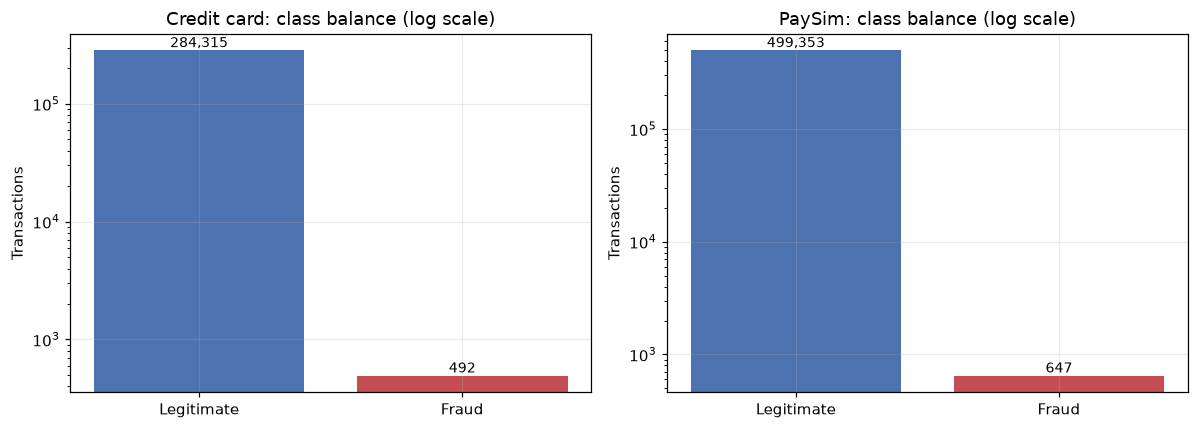

In [6]:
n_panels = 2 if ps_raw is not None else 1
fig, axes = plt.subplots(1, n_panels, figsize=(5.5 * n_panels, 4), squeeze=False)
datasets_for_plot = [("Credit card", cc_raw["Class"])] + ([("PaySim", ps_raw["isFraud"])] if ps_raw is not None else [])
for ax, (name, y) in zip(axes[0], datasets_for_plot):
    counts = y.value_counts().sort_index()
    ax.bar(["Legitimate", "Fraud"], counts.values, color=["#4C72B0", "#C44E52"])
    ax.set_yscale("log")
    ax.set_title(f"{name}: class balance (log scale)")
    ax.set_ylabel("Transactions")
    for i, v in enumerate(counts.values):
        ax.annotate(f"{v:,}", (i, v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "class_balance.png")
plt.show()

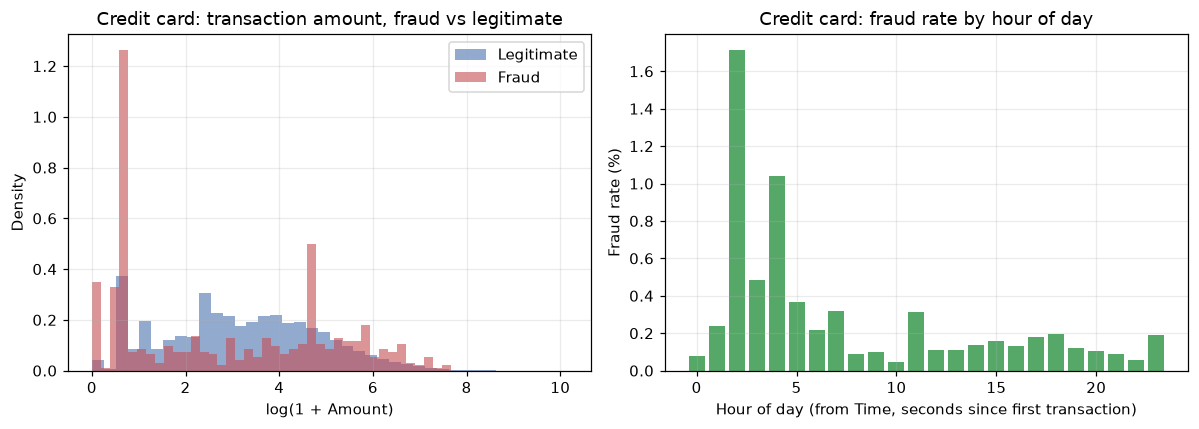

,transactions,frauds,fraud_rate
type,,,
CASH_IN,"109,939",0,0.000%
CASH_OUT,"175,646",312,0.178%
DEBIT,"3,209",0,0.000%
PAYMENT,"169,277",0,0.000%
TRANSFER,"41,929",335,0.799%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, color, name in [(0, "#4C72B0", "Legitimate"), (1, "#C44E52", "Fraud")]:
    axes[0].hist(np.log1p(cc_raw.loc[cc_raw["Class"] == label, "Amount"]), bins=40, alpha=0.6, color=color,
                 density=True, label=name)
axes[0].set_title("Credit card: transaction amount, fraud vs legitimate")
axes[0].set_xlabel("log(1 + Amount)"); axes[0].set_ylabel("Density"); axes[0].legend()

hour = (cc_raw["Time"] // 3600) % 24
rate = cc_raw.groupby(hour)["Class"].mean() * 100
axes[1].bar(rate.index, rate.values, color="#55A868")
axes[1].set_title("Credit card: fraud rate by hour of day")
axes[1].set_xlabel("Hour of day (from Time, seconds since first transaction)"); axes[1].set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eda_creditcard.png")
plt.show()

if ps_raw is not None:
    by_type = ps_raw.groupby("type")["isFraud"].agg(["count", "sum", "mean"])
    by_type.columns = ["transactions", "frauds", "fraud_rate"]
    display(by_type.style.format({"transactions": "{:,.0f}", "frauds": "{:,.0f}", "fraud_rate": "{:.3%}"}))

In PaySim, fraud appears only in `TRANSFER` and `CASH_OUT` transactions. That mirrors the
app-fraud pattern described above (money is moved out of the account), and it tells us where to
look first.

## 4. Prepare the data

* **Chronological split** (70/15/15) so the test set is the "future". Scaling and resampling are fitted on
  the training part only.
* Credit card: `log1p(Amount)` and an hour-of-day feature from `Time`.
* PaySim: log-scaled amounts and balances, one-hot `type`, and **balance-reconciliation errors**
  (`new balance + amount - old balance`). Fraud drains accounts, so these errors are strong signals.
  Identifier columns and `isFlaggedFraud` (the bank's own rule output) are dropped to avoid leakage.

In [8]:
def time_split(df, time_col, fractions=(0.70, 0.15, 0.15)):
    df = df.sort_values(time_col, kind="stable").reset_index(drop=True)
    n = len(df)
    a, b = int(n * fractions[0]), int(n * (fractions[0] + fractions[1]))
    return df.iloc[:a].copy(), df.iloc[a:b].copy(), df.iloc[b:].copy()


def slog(x):                                   # signed log, for balance errors that can be negative
    return np.sign(x) * np.log1p(np.abs(x))


def prep_creditcard(df):
    X = df.drop(columns=["Class"]).copy()
    X["Amount"] = np.log1p(X["Amount"])
    X["hour"] = (X["Time"] // 3600) % 24
    return X.drop(columns=["Time"]), df["Class"].astype(int).to_numpy()


PS_TYPES = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]


def prep_paysim(df, balance_features=True):
    X = pd.DataFrame(index=df.index)
    X["amount"] = np.log1p(df["amount"])
    X["hour"] = df["step"] % 24
    for t in PS_TYPES:
        X["type_" + t] = (df["type"] == t).astype(int)
    X["oldbalanceOrg"] = np.log1p(df["oldbalanceOrg"])
    X["oldbalanceDest"] = np.log1p(df["oldbalanceDest"])
    if balance_features:
        X["newbalanceOrig"] = np.log1p(df["newbalanceOrig"])
        X["newbalanceDest"] = np.log1p(df["newbalanceDest"])
        X["errorBalanceOrig"] = slog(df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"])
        X["errorBalanceDest"] = slog(df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"])
    return X, df["isFraud"].astype(int).to_numpy()


def build_splits(raw, time_col, prep, **kw):
    tr, va, te = time_split(raw, time_col)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = prep(tr, **kw), prep(va, **kw), prep(te, **kw)
    return dict(Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte)


def describe_splits(name, s):
    print(f"{name}")
    for part in ("tr", "va", "te"):
        y = s["y" + part]
        print(f"  {part:>2}: {len(y):>9,} rows | {int(y.sum()):>5,} frauds ({y.mean():.4%})")


DATA = {"Credit card": build_splits(cc_raw, "Time", prep_creditcard)}
if ps_raw is not None:
    DATA["PaySim"] = build_splits(ps_raw, "step", prep_paysim)

for name, s in DATA.items():
    describe_splits(name, s)

Credit card
  tr:   199,364 rows |   384 frauds (0.1926%)
  va:    42,721 rows |    56 frauds (0.1311%)
  te:    42,722 rows |    52 frauds (0.1217%)
PaySim
  tr:   350,000 rows |   279 frauds (0.0797%)
  va:    75,000 rows |    47 frauds (0.0627%)
  te:    75,000 rows |   321 frauds (0.4280%)


Check the counts above: every split needs a reasonable number of frauds. With only a few dozen frauds in
the test set, results are noisy, which is why confidence intervals are reported in section 7.

## 5. Models

Each model deals with imbalance in a different way:

| Model | How imbalance is handled |
|---|---|
| Logistic Regression | `class_weight="balanced"` (fraud errors cost more) |
| Logistic Regression + SMOTE | Synthetic fraud examples added to the training set only |
| Random Forest | `class_weight="balanced_subsample"` |
| XGBoost | `scale_pos_weight` = legitimate / fraud ratio, early stopping on validation PR-AUC |
| Keras MLP | `class_weight` in `fit`, early stopping on validation PR-AUC |

In [9]:
class KerasMLP:
    """Small Keras MLP with class weights and early stopping, exposing predict_proba like scikit-learn."""

    def __init__(self, hidden=(64, 32), dropout=0.2, epochs=30, batch_size=2048, lr=1e-3):
        self.hidden, self.dropout, self.epochs, self.batch_size, self.lr = hidden, dropout, epochs, batch_size, lr

    def _scale(self, X):
        return np.clip(self.scaler.transform(X), -5, 5).astype("float32")

    def fit(self, X, y, X_val, y_val):
        self.scaler = StandardScaler().fit(X)
        keras.utils.set_random_seed(SEED)
        model = keras.Sequential([layers.Input(shape=(X.shape[1],))] +
                                 [l for h in self.hidden for l in (layers.Dense(h, activation="relu"), layers.Dropout(self.dropout))] +
                                 [layers.Dense(1, activation="sigmoid")])
        model.compile(optimizer=keras.optimizers.Adam(self.lr), loss="binary_crossentropy",
                      metrics=[keras.metrics.AUC(name="prc", curve="PR")])
        neg, pos = (y == 0).sum(), (y == 1).sum()
        weights = {0: (1 / neg) * len(y) / 2.0, 1: (1 / pos) * len(y) / 2.0}      # as in the TensorFlow tutorial
        early = keras.callbacks.EarlyStopping(monitor="val_prc", mode="max", patience=4, restore_best_weights=True)
        self.history = model.fit(self._scale(X), y, validation_data=(self._scale(X_val), y_val),
                                 epochs=self.epochs, batch_size=self.batch_size, class_weight=weights,
                                 callbacks=[early], verbose=0)
        self.model = model
        return self

    def predict_proba(self, X):
        p = self.model.predict(self._scale(X), batch_size=8192, verbose=0).ravel()
        return np.column_stack([1 - p, p])


def build_models(ytr):
    spw = (ytr == 0).sum() / max((ytr == 1).sum(), 1)
    return {
        "Logistic Regression (class weights)": Pipeline([("scale", StandardScaler()),
            ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
        "Logistic Regression + SMOTE": ImbPipeline([("scale", StandardScaler()),
            ("smote", SMOTE(sampling_strategy=0.1, k_neighbors=5, random_state=SEED)),
            ("clf", LogisticRegression(max_iter=2000))]),
        "Random Forest (balanced)": RandomForestClassifier(n_estimators=150, min_samples_leaf=3, max_samples=0.5,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "XGBoost (scale_pos_weight)": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5,
            subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="aucpr",
            early_stopping_rounds=30, tree_method="hist", n_jobs=-1, random_state=SEED),
        "Keras MLP (class weights)": KerasMLP(),
    }


def fit_model(name, model, s):
    t0 = time.time()
    if name.startswith("XGBoost"):
        model.fit(s["Xtr"], s["ytr"], eval_set=[(s["Xva"], s["yva"])], verbose=False)
    elif name.startswith("Keras"):
        model.fit(s["Xtr"], s["ytr"], s["Xva"], s["yva"])
    else:
        model.fit(s["Xtr"], s["ytr"])
    return time.time() - t0


FITTED = {}      # FITTED[dataset][model_name] = dict(model, val, test, seconds)
for ds_name, s in DATA.items():
    FITTED[ds_name] = {}
    print(f"\n=== {ds_name} ===")
    for m_name, model in build_models(s["ytr"]).items():
        secs = fit_model(m_name, model, s)
        FITTED[ds_name][m_name] = dict(model=model, seconds=secs,
                                       val=model.predict_proba(s["Xva"])[:, 1],
                                       test=model.predict_proba(s["Xte"])[:, 1])
        print(f"  {m_name:<38} trained in {secs:6.1f}s")


=== Credit card ===
  Logistic Regression (class weights)    trained in    1.8s
  Logistic Regression + SMOTE            trained in    5.2s
  Random Forest (balanced)               trained in   35.3s
  XGBoost (scale_pos_weight)             trained in    8.9s
  Keras MLP (class weights)              trained in   16.4s

=== PaySim ===
  Logistic Regression (class weights)    trained in    2.2s
  Logistic Regression + SMOTE            trained in    1.4s
  Random Forest (balanced)               trained in   18.5s
  XGBoost (scale_pos_weight)             trained in    2.2s
  Keras MLP (class weights)              trained in   39.2s


## 6. Evaluate

* **PR-AUC** (average precision) is the headline metric. A model with no skill scores the fraud rate
  (for example 0.17%), not 0.5 as ROC-AUC suggests.
* **Precision, recall and F1** use a threshold chosen on the **validation** set (best F1), then applied
  unchanged to the test set.
* **Alert budget:** if investigators can only review the top 0.5% riskiest transactions, how much fraud
  do they catch (recall) and how many alerts are real (precision)?
* **Accuracy** is shown only to demonstrate why it is misleading here.

In [10]:
def best_f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return t[int(np.nanargmax(f1))]


def alert_budget(y, s, frac):
    k = max(1, int(len(y) * frac))
    top = np.argsort(-s)[:k]
    tp = y[top].sum()
    return tp / max(y.sum(), 1), tp / k           # recall, precision


def bootstrap_ap(y, s, n=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_pos, idx_neg = np.where(y == 1)[0], np.where(y == 0)[0]
    out = []
    for _ in range(n):                              # resample frauds and legitimate separately
        i = np.concatenate([rng.choice(idx_pos, len(idx_pos)), rng.choice(idx_neg, len(idx_neg))])
        out.append(average_precision_score(y[i], s[i]))
    return np.percentile(out, [2.5, 97.5])


def evaluate(ds_name):
    s = DATA[ds_name]
    rows = []
    for m_name, r in FITTED[ds_name].items():
        thr = best_f1_threshold(s["yva"], r["val"])
        pred = (r["test"] >= thr).astype(int)
        rec_b, prec_b = alert_budget(s["yte"], r["test"], 0.005)
        lo, hi = bootstrap_ap(s["yte"], r["test"])
        rows.append({"Model": m_name,
                     "PR-AUC": average_precision_score(s["yte"], r["test"]),
                     "PR-AUC 95% CI": f"{lo:.3f} to {hi:.3f}",
                     "ROC-AUC": roc_auc_score(s["yte"], r["test"]),
                     "Precision": precision_score(s["yte"], pred, zero_division=0),
                     "Recall": recall_score(s["yte"], pred),
                     "F1": f1_score(s["yte"], pred, zero_division=0),
                     "Recall @0.5% alerts": rec_b,
                     "Precision @0.5% alerts": prec_b,
                     "Accuracy": accuracy_score(s["yte"], pred),
                     "Train time (s)": r["seconds"]})
    return pd.DataFrame(rows).set_index("Model")


RESULTS = {ds: evaluate(ds) for ds in DATA}
fmt = {c: "{:.3f}" for c in ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "Recall @0.5% alerts",
                              "Precision @0.5% alerts", "Accuracy"]}
fmt["Train time (s)"] = "{:.1f}"
for ds, table in RESULTS.items():
    prevalence = DATA[ds]["yte"].mean()
    print(f"\n{ds}: test fraud rate = {prevalence:.4%}  (a no-skill model has PR-AUC about {prevalence:.4f})")
    display(table.sort_values("PR-AUC", ascending=False).style.format(fmt))
    table.to_csv(RESULTS_DIR / f"results_{ds.lower().replace(' ', '_')}.csv")


Credit card: test fraud rate = 0.1217%  (a no-skill model has PR-AUC about 0.0012)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,Precision,Recall,F1,Recall @0.5% alerts,Precision @0.5% alerts,Accuracy,Train time (s)
Model,,,,,,,,,,
Keras MLP (class weights),0.774,0.670 to 0.867,0.976,1.000,0.615,0.762,0.808,0.197,1.000,16.4
Random Forest (balanced),0.772,0.677 to 0.863,0.955,0.867,0.750,0.804,0.827,0.202,1.000,35.3
XGBoost (scale_pos_weight),0.757,0.656 to 0.852,0.979,0.867,0.750,0.804,0.788,0.192,1.000,8.9
Logistic Regression (class weights),0.694,0.572 to 0.821,0.978,0.946,0.673,0.787,0.808,0.197,1.000,1.8
Logistic Regression + SMOTE,0.686,0.579 to 0.790,0.973,0.745,0.673,0.707,0.788,0.192,0.999,5.2



PaySim: test fraud rate = 0.4280%  (a no-skill model has PR-AUC about 0.0043)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,Precision,Recall,F1,Recall @0.5% alerts,Precision @0.5% alerts,Accuracy,Train time (s)
Model,,,,,,,,,,
Random Forest (balanced),1.000,1.000 to 1.000,1.000,1.000,0.994,0.997,1.000,0.856,1.000,18.5
XGBoost (scale_pos_weight),1.000,0.999 to 1.000,1.000,0.994,0.991,0.992,1.000,0.856,1.000,2.2
Keras MLP (class weights),0.999,0.999 to 1.000,1.000,0.994,0.984,0.989,1.000,0.856,1.000,39.2
Logistic Regression + SMOTE,0.997,0.991 to 1.000,1.000,0.978,0.978,0.978,0.997,0.853,1.000,1.4
Logistic Regression (class weights),0.981,0.967 to 0.990,1.000,0.930,0.988,0.958,0.994,0.851,1.000,2.2


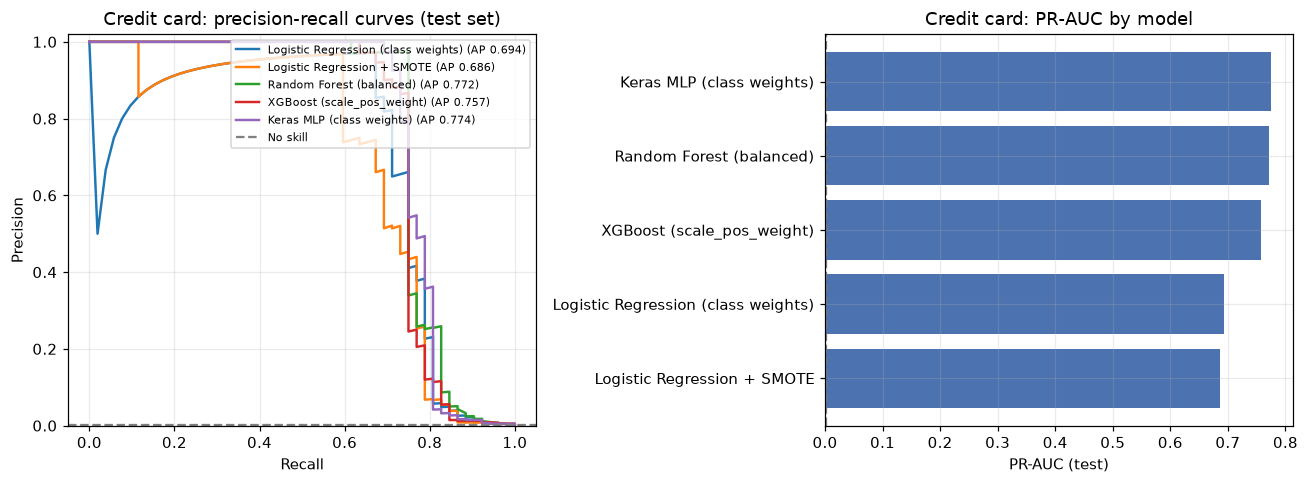

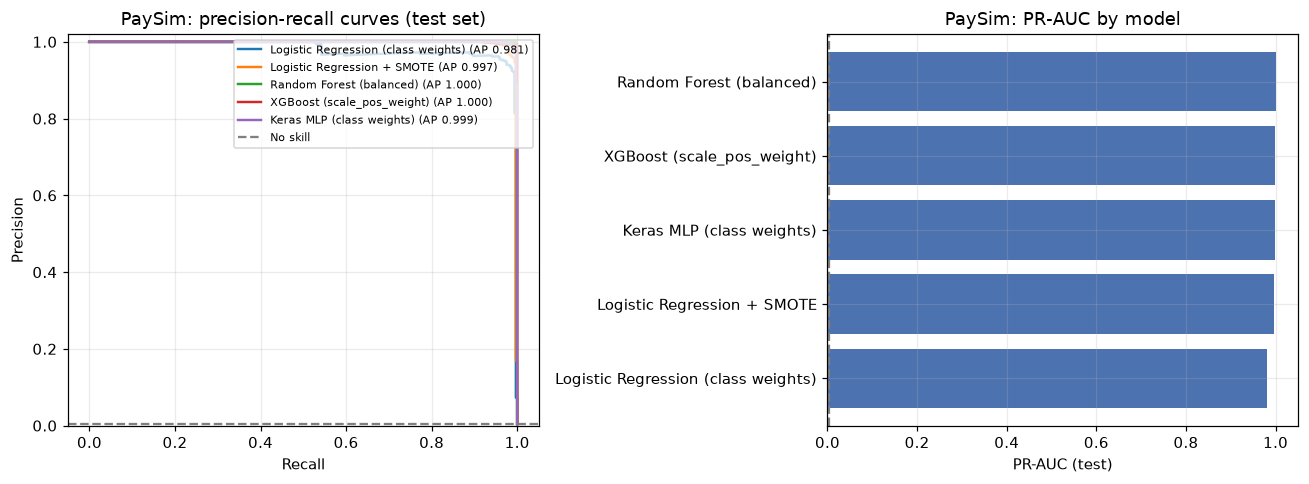

In [11]:
for ds, s in DATA.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for m_name, r in FITTED[ds].items():
        p, rc, _ = precision_recall_curve(s["yte"], r["test"])
        axes[0].plot(rc, p, label=f"{m_name} (AP {average_precision_score(s['yte'], r['test']):.3f})", lw=1.6)
    axes[0].axhline(s["yte"].mean(), color="grey", ls="--", label="No skill")
    axes[0].set(xlabel="Recall", ylabel="Precision", title=f"{ds}: precision-recall curves (test set)", ylim=(0, 1.02))
    axes[0].legend(fontsize=7.5, loc="upper right")

    order = RESULTS[ds].sort_values("PR-AUC")
    axes[1].barh(order.index, order["PR-AUC"], color="#4C72B0")
    axes[1].axvline(s["yte"].mean(), color="grey", ls="--")
    axes[1].set(xlabel="PR-AUC (test)", title=f"{ds}: PR-AUC by model")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"pr_curves_{ds.lower().replace(' ', '_')}.png")
    plt.show()

### The accuracy trap

In [12]:
rows = []
for ds, s in DATA.items():
    best = RESULTS[ds]["PR-AUC"].idxmax()
    rows.append({"Dataset": ds,
                 "Accuracy of 'always legitimate'": 1 - s["yte"].mean(),
                 "Recall of 'always legitimate'": 0.0,
                 f"Accuracy of best model": RESULTS[ds].loc[best, "Accuracy"],
                 "Recall of best model": RESULTS[ds].loc[best, "Recall"],
                 "Best model (by PR-AUC)": best})
display(pd.DataFrame(rows).set_index("Dataset").style.format(
    {c: "{:.4f}" for c in ["Accuracy of 'always legitimate'", "Accuracy of best model", "Recall of best model", "Recall of 'always legitimate'"]}))

,Accuracy of 'always legitimate',Recall of 'always legitimate',Accuracy of best model,Recall of best model,Best model (by PR-AUC)
Dataset,,,,,
Credit card,0.9988,0.0000,0.9995,0.6154,Keras MLP (class weights)
PaySim,0.9957,0.0000,1.0000,0.9938,Random Forest (balanced)


A model that approves every transaction scores very high accuracy and catches no fraud at all. That is why
the headline metric here is PR-AUC, supported by precision and recall.

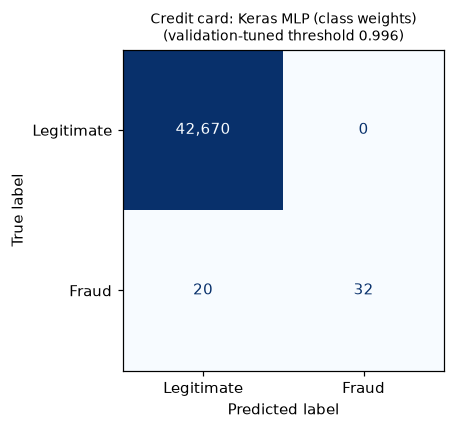

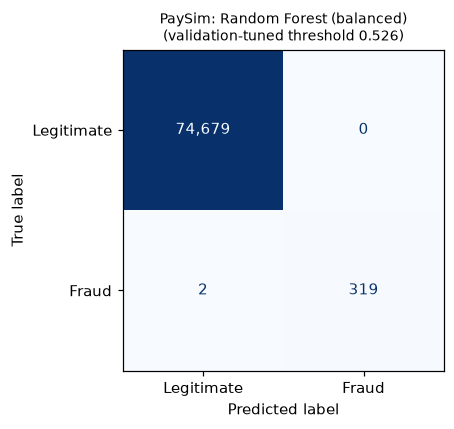

In [13]:
for ds, s in DATA.items():
    best = RESULTS[ds]["PR-AUC"].idxmax()
    thr = best_f1_threshold(s["yva"], FITTED[ds][best]["val"])
    pred = (FITTED[ds][best]["test"] >= thr).astype(int)
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(confusion_matrix(s["yte"], pred), display_labels=["Legitimate", "Fraud"]).plot(
        ax=ax, values_format=",d", cmap="Blues", colorbar=False)
    ax.set_title(f"{ds}: {best}\n(validation-tuned threshold {thr:.3f})", fontsize=9)
    ax.grid(False)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"confusion_{ds.lower().replace(' ', '_')}.png")
    plt.show()

## 7. Explain the decisions

Banks must be able to justify why a payment was flagged. XGBoost can return exact TreeSHAP contributions
(`pred_contribs=True`), so no extra library is needed. The first chart shows which features matter overall;
the second explains the single highest-risk transaction in the test set.

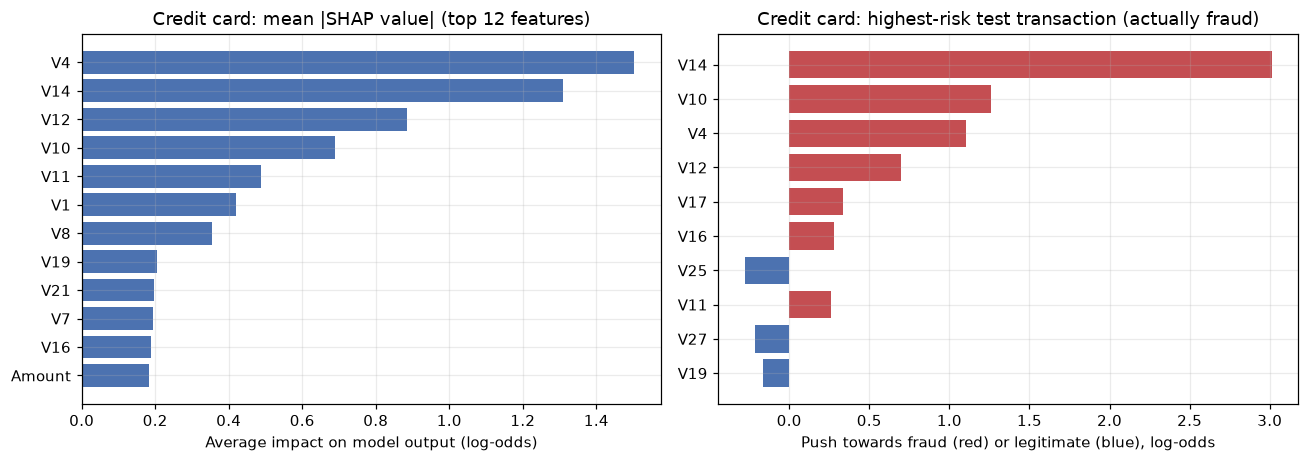

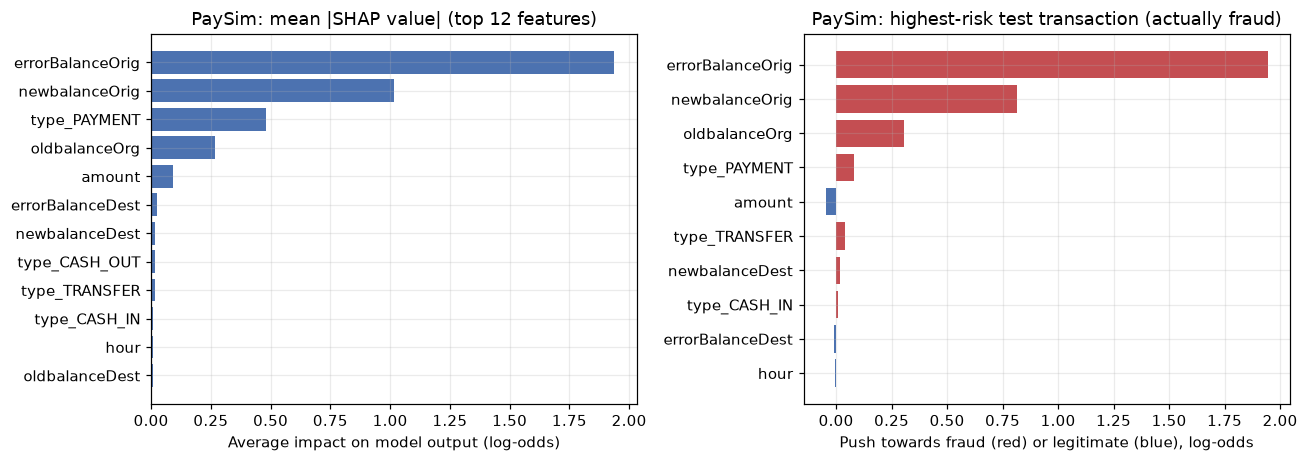

In [14]:
XGB_NAME = "XGBoost (scale_pos_weight)"
for ds, s in DATA.items():
    model = FITTED[ds][XGB_NAME]["model"]
    Xte = s["Xte"]
    rng = np.random.default_rng(SEED)
    sample_idx = rng.choice(len(Xte), size=min(5000, len(Xte)), replace=False)
    booster = model.get_booster()
    contrib = booster.predict(xgb.DMatrix(Xte.iloc[sample_idx], feature_names=list(Xte.columns)), pred_contribs=True)[:, :-1]
    global_imp = pd.Series(np.abs(contrib).mean(axis=0), index=Xte.columns).sort_values().tail(12)

    top_i = int(np.argmax(FITTED[ds][XGB_NAME]["test"]))
    local = booster.predict(xgb.DMatrix(Xte.iloc[[top_i]], feature_names=list(Xte.columns)), pred_contribs=True)[0, :-1]
    local = pd.Series(local, index=Xte.columns)
    local = local.reindex(local.abs().sort_values().tail(10).index)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    axes[0].barh(global_imp.index, global_imp.values, color="#4C72B0")
    axes[0].set(title=f"{ds}: mean |SHAP value| (top 12 features)", xlabel="Average impact on model output (log-odds)")
    axes[1].barh(local.index, local.values, color=np.where(local.values > 0, "#C44E52", "#4C72B0"))
    actual = "fraud" if s["yte"][top_i] == 1 else "legitimate"
    axes[1].set(title=f"{ds}: highest-risk test transaction (actually {actual})",
                xlabel="Push towards fraud (red) or legitimate (blue), log-odds")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"explain_{ds.lower().replace(' ', '_')}.png")
    plt.show()

## 8. Ablation: how much does PaySim rely on balance features?

In PaySim, the account balances before and after a payment practically give away fraud. A real bank may not
have such clean fields. This check retrains XGBoost **without** the new-balance and error features.

In [15]:
if "PaySim" in DATA:
    s2 = build_splits(ps_raw, "step", prep_paysim, balance_features=False)
    m = build_models(s2["ytr"])[XGB_NAME]
    fit_model(XGB_NAME, m, s2)
    ap_without = average_precision_score(s2["yte"], m.predict_proba(s2["Xte"])[:, 1])
    ap_with = RESULTS["PaySim"].loc[XGB_NAME, "PR-AUC"]
    display(pd.DataFrame({"XGBoost PR-AUC": [ap_with, ap_without]},
                         index=["With balance + error features", "Without them"]).style.format("{:.3f}"))
else:
    print("PaySim not loaded, ablation skipped.")

,XGBoost PR-AUC
With balance + error features,1.000
Without them,0.860


## 9. Summary table and files written

In [16]:
summary = []
for ds in DATA:
    t = RESULTS[ds]
    best = t["PR-AUC"].idxmax()
    summary.append({"Dataset": ds, "Best model (PR-AUC)": best, "PR-AUC": t.loc[best, "PR-AUC"],
                    "Precision": t.loc[best, "Precision"], "Recall": t.loc[best, "Recall"],
                    "Recall @0.5% alerts": t.loc[best, "Recall @0.5% alerts"]})
summary = pd.DataFrame(summary).set_index("Dataset")
display(summary.style.format({c: "{:.3f}" for c in ["PR-AUC", "Precision", "Recall", "Recall @0.5% alerts"]}))
summary.to_csv(RESULTS_DIR / "summary.csv")
print("Files written to", RESULTS_DIR.resolve())
print(sorted(p.name for p in RESULTS_DIR.iterdir()))

,Best model (PR-AUC),PR-AUC,Precision,Recall,Recall @0.5% alerts
Dataset,,,,,
Credit card,Keras MLP (class weights),0.774,1.000,0.615,0.808
PaySim,Random Forest (balanced),1.000,1.000,0.994,1.000


Files written to C:\Users\makha\Downloads\fraud_detection_project1\fraud_project\results
['class_balance.png', 'confusion_credit_card.png', 'confusion_paysim.png', 'eda_creditcard.png', 'explain_credit_card.png', 'explain_paysim.png', 'pr_curves_credit_card.png', 'pr_curves_paysim.png', 'results_credit_card.csv', 'results_paysim.csv', 'summary.csv']


## 10. Discussion (write this after you have run the notebook on the real data)

Use the tables and charts above to answer:

1. **Which imbalance strategy worked best, and by how much?** Compare class weights, SMOTE and the
   tree models using PR-AUC with its confidence interval, not a single number. If two intervals overlap, the
   models are not clearly different.
2. **What does the precision-recall trade-off mean in practice?** At the chosen threshold, how many
   genuine customers are inconvenienced for each fraud caught? What happens at the 0.5% alert budget?
3. **What drives the predictions?** Use the SHAP charts. Do the important features make sense?
4. **How much do the results depend on the dataset?** Compare the credit card result (anonymised
   features) with PaySim, and read the ablation.

### Limitations to state in your report

* The credit card data is European card transactions from 2013, with anonymised PCA features. PaySim is
  **synthetic**. Neither contains South African app-based social-engineering fraud, so the results show the
  methods, not how they would perform at a South African bank.
* The credit card test set contains only a few dozen frauds, so metrics are noisy. Report the confidence
  intervals.
* PaySim fraud is almost separable from balance fields, so scores near 1.0 say little about real-world difficulty.
* The threshold was tuned for F1. A bank would pick it from the relative cost of a missed fraud versus a
  blocked genuine payment.
* Concept drift (fraud tactics change) is only partly tested by the chronological split.

### Reference

SABRIC figures (110,074 incidents, R2.41bn claims, +29.2% on 2024, apps about 89% of cases) as reported by
[Joburg ETC](https://www.joburgetc.com/business/banking-apps-drive-surge-in-digital-bank-fraud-2025/).